# Module 04: Leakage-Safe In-Trip Future SOC Forecasting

## Objective

Given the SOC and operating conditions observed during the first 25%, 50%, or 75% of a journey, estimate **arrival SOC** at trip completion. This is an *in-trip* prediction task, not a pre-trip prediction and not a one-sample-ahead forecast.

The Munich dataset contains 70 trips. Following the established quality checks, `TripA31`, `TripB04`, and `TripB09` are excluded; the modelling population is 67 valid discharge-dominant trips. Munich has no direct SOH, capacity, or degradation target: SOC is a charge-state measurement, while arrival SOC is the prediction target here.

### Leakage-safe pipeline

Observed vehicle state → observed-prefix features → arrival-SOC prediction → battery/energy decision support

Every predictor is calculated from telemetry at or before the relevant progress cutoff. Full-trip SOC summaries, full-trip duration/distance, and future telemetry are never used as predictors.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

MODULE_DIR = Path.cwd()
if not (MODULE_DIR / "Overview.xlsx").exists():
    MODULE_DIR = Path.cwd() / "module_01"
OVERVIEW_PATH = MODULE_DIR / "Overview.xlsx"
TRIP_FILES = sorted(list(MODULE_DIR.glob("TripA*.csv")) + list(MODULE_DIR.glob("TripB*.csv")))
assert OVERVIEW_PATH.exists() and len(TRIP_FILES) == 70
print(f"Dataset directory: {MODULE_DIR}")
print(f"Telemetry trips: {len(TRIP_FILES)}")

Dataset directory: C:\Users\gayat\projects\get_into\FIP\module_01
Telemetry trips: 70


## 1. Load and validate the established trip population

Telemetry is sorted by time and the known malformed velocity header is normalized. The valid-trip decision is reproduced explicitly, so this notebook remains self-contained.

In [2]:
overview = pd.read_excel(OVERVIEW_PATH).dropna(how="all").dropna(axis=1, how="all").reset_index(drop=True)
if "Unnamed: 8" in overview.columns:
    overview = overview.rename(columns={"Unnamed: 8": "SoC Change"})

trip_data = {}
for path in TRIP_FILES:
    frame = pd.read_csv(path, sep=";", encoding="cp1252")
    frame.columns = frame.columns.str.strip()
    if "Velocity [km/h]]]" in frame.columns:
        frame = frame.rename(columns={"Velocity [km/h]]]": "Velocity [km/h]"})
    frame = frame.sort_values("Time [s]").reset_index(drop=True)
    trip_data[path.stem] = frame

assert set(overview["Trip"].astype(str)) == set(trip_data)
EXCLUDED_TRIPS = {"TripA31", "TripB04", "TripB09"}
valid_trips = sorted(set(trip_data) - EXCLUDED_TRIPS)
assert len(valid_trips) == 67
arrival_soc_lookup = pd.to_numeric(
    overview.set_index("Trip")["Battery State of Charge (End)"], errors="coerce"
)
assert arrival_soc_lookup.loc[valid_trips].notna().all()
print(f"Overview trips: {len(overview)} | Valid modelling trips: {len(valid_trips)}")
print("Excluded after established direction/consistency checks:", sorted(EXCLUDED_TRIPS))

Overview trips: 70 | Valid modelling trips: 67
Excluded after established direction/consistency checks: ['TripA31', 'TripB04', 'TripB09']


## 2. Leakage-safe prefix feature construction

At each horizon, a trip is truncated at normalized time progress. All summary statistics, current values, elapsed time, and distance are computed from that observed prefix only. Arrival SOC is read at the final telemetry sample and is stored only as the target.

In [3]:
CHANNELS = {
    "battery_voltage": "Battery Voltage [V]",
    "battery_current": "Battery Current [A]",
    "battery_temperature": "Battery Temperature [°C]",
    "max_battery_temperature": "max. Battery Temperature [°C]",
    "velocity": "Velocity [km/h]",
    "throttle": "Throttle [%]",
    "motor_torque": "Motor Torque [Nm]",
    "acceleration": "Longitudinal Acceleration [m/s^2]",
    "heating_power": "Heating Power CAN [kW]",
    "requested_heating": "Requested Heating Power [W]",
    "aircon_power": "AirCon Power [kW]",
    "ambient_temperature": "Ambient Temperature [°C]",
    "heat_exchanger_temperature": "Heat Exchanger Temperature [°C]",
    "cabin_temperature": "Cabin Temperature Sensor [°C]",
    "heater_signal": "Heater Signal",
}

# Retain only telemetry channels available for every valid trip so the feature
# matrix has a consistent, missing-value-free schema across all 67 samples.
CHANNELS = {
    name: column for name, column in CHANNELS.items()
    if all(column in trip_data[trip].columns for trip in valid_trips)
}
print("Prefix channels available in every valid trip:", len(CHANNELS))

FORBIDDEN_FEATURE_TOKENS = ("soc_end", "full_trip", "arrival", "target", "final_duration", "final_distance")

def numeric(series):
    return pd.to_numeric(series, errors="coerce").astype(float)

def interpolate_at(time, values, target_time):
    valid = np.isfinite(time) & np.isfinite(values)
    return float(np.interp(target_time, time[valid], values[valid]))

def prefix_features(trip, frame, horizon):
    time = numeric(frame["Time [s]"]).to_numpy()
    assert np.all(np.diff(time) >= 0)
    start, end = float(time[0]), float(time[-1])
    cutoff_time = start + horizon * (end - start)
    prefix = frame.loc[time <= cutoff_time].copy()
    assert not prefix.empty
    prefix_time = numeric(prefix["Time [s]"]).to_numpy()
    values = {}

    soc = numeric(frame["SoC [%]"]).to_numpy()
    soc_prefix = numeric(prefix["SoC [%]"]).to_numpy()
    # Use the final row at or before the cutoff. This deliberately avoids
    # interpolation with the following (future) telemetry sample.
    soc_current = float(soc_prefix[np.isfinite(soc_prefix)][-1])
    values.update({
        "soc_start": float(soc_prefix[0]),
        "soc_current": soc_current,
        "soc_change_observed": float(soc_prefix[0] - soc_current),
        "soc_min_observed": float(np.nanmin(soc_prefix)),
        "soc_max_observed": float(np.nanmax(soc_prefix)),
        "elapsed_time_observed_s": cutoff_time - start,
        "progress_fraction": horizon,
    })

    velocity = numeric(prefix[CHANNELS["velocity"]]).to_numpy()
    values["distance_observed_km"] = float(np.trapz(np.clip(velocity, 0, None), prefix_time) / 3600)

    for name, column in CHANNELS.items():
        if column not in prefix.columns:
            continue
        series = numeric(prefix[column]).to_numpy()
        if not np.isfinite(series).all():
            raise ValueError(f"{trip}: non-numeric or missing values in {column}")
        values[f"{name}_current"] = float(series[-1])
        values[f"{name}_mean_observed"] = float(np.mean(series))
        values[f"{name}_min_observed"] = float(np.min(series))
        values[f"{name}_max_observed"] = float(np.max(series))
        values[f"{name}_std_observed"] = float(np.std(series))

    dt = np.diff(prefix_time)
    acceleration = numeric(prefix[CHANNELS["acceleration"]]).to_numpy()
    jerk = np.diff(acceleration) / dt
    values["jerk_mean_observed"] = float(np.mean(jerk))
    values["jerk_std_observed"] = float(np.std(jerk))
    values["speed_above_50_fraction_observed"] = float(np.mean(velocity > 50))
    values["stationary_fraction_observed"] = float(np.mean(velocity <= 1))

    # Target is intentionally returned separately and never added to values.
    # Endpoint SOC is the overview's recorded end-of-trip SOC. It is the
    # prediction target only, never an input feature.
    arrival_soc = float(arrival_soc_lookup.loc[trip])
    audit = {"Trip": trip, "Horizon": horizon, "cutoff_time_s": cutoff_time,
             "max_feature_timestamp_s": float(prefix_time.max()), "arrival_timestamp_s": end}
    return values, arrival_soc, audit

def build_horizon_dataset(horizon):
    rows, targets, audits = [], [], []
    for trip in valid_trips:
        features, target, audit = prefix_features(trip, trip_data[trip], horizon)
        rows.append({"Trip": trip, **features})
        targets.append(target)
        audits.append(audit)
    X = pd.DataFrame(rows).set_index("Trip").sort_index()
    y = pd.Series(targets, index=X.index, name="arrival_soc")
    audit = pd.DataFrame(audits).set_index("Trip").loc[X.index]
    # A telemetry channel can be present but be unrecorded for part of the
    # dataset. Drop such a feature globally rather than impute before splitting.
    incomplete = X.columns[X.isna().any()].tolist()
    if incomplete:
        print(f"{int(horizon*100)}%: removing {len(incomplete)} incomplete prefix features")
        X = X.drop(columns=incomplete)
    assert X.notna().all().all() and y.notna().all()
    assert not any(token in col.lower() for col in X.columns for token in FORBIDDEN_FEATURE_TOKENS)
    return X, y, audit

datasets = {h: build_horizon_dataset(h) for h in (0.25, 0.50, 0.75)}
for h, (X, y, audit) in datasets.items():
    print(f"{int(h*100)}% observed: X={X.shape}, target range=({y.min():.2f}, {y.max():.2f})")

Prefix channels available in every valid trip: 15


25%: removing 2 incomplete prefix features


50%: removing 2 incomplete prefix features


75%: removing 2 incomplete prefix features
25% observed: X=(67, 85), target range=(0.15, 0.83)
50% observed: X=(67, 85), target range=(0.15, 0.83)
75% observed: X=(67, 85), target range=(0.15, 0.83)


## 3. Mandatory leakage validation

The assertions below verify the central forecasting rule: the last timestamp contributing to any feature must be no later than its cutoff. They also verify that full-trip SOC/target-derived predictors are absent. Train-only fitting is enforced in the modelling pipelines that follow.

In [4]:
for horizon, (X, _, audit) in datasets.items():
    timestamp_ok = (audit["max_feature_timestamp_s"] <= audit["cutoff_time_s"] + 1e-9).all()
    no_future_target = (audit["arrival_timestamp_s"] >= audit["cutoff_time_s"]).all()
    no_forbidden = not any(token in col.lower() for col in X.columns for token in FORBIDDEN_FEATURE_TOKENS)
    print(f"{int(horizon*100)}% horizon | prefix timestamps: {'PASS' if timestamp_ok else 'FAIL'} | "
          f"target after cutoff: {'PASS' if no_future_target else 'FAIL'} | forbidden features absent: {'PASS' if no_forbidden else 'FAIL'}")
    assert timestamp_ok and no_future_target and no_forbidden
print("PASS: prefix engineering uses no future observations; preprocessing is fit inside training-only pipelines.")

25% horizon | prefix timestamps: PASS | target after cutoff: PASS | forbidden features absent: PASS
50% horizon | prefix timestamps: PASS | target after cutoff: PASS | forbidden features absent: PASS
75% horizon | prefix timestamps: PASS | target after cutoff: PASS | forbidden features absent: PASS
PASS: prefix engineering uses no future observations; preprocessing is fit inside training-only pipelines.


## 4. Centralized Elastic Net: train-only tuning and untouched test evaluation

For every horizon, the same 53/14 trip split (`random_state=42`) is used. A mean baseline and Elastic Net pipeline are tuned using five-fold CV on training trips only. The test trips are held out until final evaluation.

In [5]:
ALPHAS = [0.0001, 0.0003, 0.001, 0.003, 0.01]
L1_RATIOS = [0.1, 0.3, 0.5, 0.7, 0.9]
trip_ids = np.array(sorted(valid_trips))
train_ids, test_ids = train_test_split(trip_ids, test_size=0.20, random_state=RANDOM_STATE)
assert len(train_ids) == 53 and len(test_ids) == 14 and not set(train_ids) & set(test_ids)

def metrics(y_true, prediction):
    return {"MAE": mean_absolute_error(y_true, prediction),
            "RMSE": np.sqrt(mean_squared_error(y_true, prediction)),
            "R2": r2_score(y_true, prediction)}

central_results, central_models, predictions = [], {}, {}
for horizon, (X, y, _) in datasets.items():
    X_train, X_test = X.loc[train_ids], X.loc[test_ids]
    y_train, y_test = y.loc[train_ids], y.loc[test_ids]
    pipeline = Pipeline([("scaler", StandardScaler()), ("model", ElasticNet(max_iter=20000, random_state=RANDOM_STATE))])
    search = GridSearchCV(pipeline, {"model__alpha": ALPHAS, "model__l1_ratio": L1_RATIOS},
                          scoring="neg_mean_absolute_error", cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1)
    search.fit(X_train, y_train)
    model = search.best_estimator_
    prediction = model.predict(X_test)
    baseline_prediction = np.repeat(y_train.mean(), len(y_test))
    result = {"Horizon": f"{int(horizon*100)}% → 100%", "Observed": f"{int(horizon*100)}%", "Target": "Arrival SOC",
              "Features": X.shape[1], "Train trips": len(X_train), "Test trips": len(X_test),
              "alpha": model.named_steps["model"].alpha, "l1_ratio": model.named_steps["model"].l1_ratio,
              **metrics(y_test, prediction),
              **{f"Baseline {k}": v for k, v in metrics(y_test, baseline_prediction).items()}}
    central_results.append(result)
    central_models[horizon] = model
    predictions[horizon] = pd.DataFrame({"Trip": test_ids, "Actual arrival SOC": y_test.values, "Predicted arrival SOC": prediction})

central_table = pd.DataFrame(central_results).set_index("Horizon")
display(central_table.round(4))

,Observed,Target,Features,Train trips,Test trips,alpha,l1_ratio,MAE,RMSE,R2,Baseline MAE,Baseline RMSE,Baseline R2
Horizon,,,,,,,,,,,,,
25% → 100%,25%,Arrival SOC,85,53,14,0.01,0.5,0.0254,0.0355,0.9316,0.1163,0.1419,-0.0912
50% → 100%,50%,Arrival SOC,85,53,14,0.01,0.7,0.0148,0.0211,0.9759,0.1163,0.1419,-0.0912
75% → 100%,75%,Arrival SOC,85,53,14,0.01,0.3,0.0122,0.0171,0.9841,0.1163,0.1419,-0.0912


## 5. Centralized evaluation and interpretability

Predictions are assessed only on the untouched global test trips. Coefficients describe predictive associations in this dataset; they are not causal effects of driving or HVAC variables on SOC.

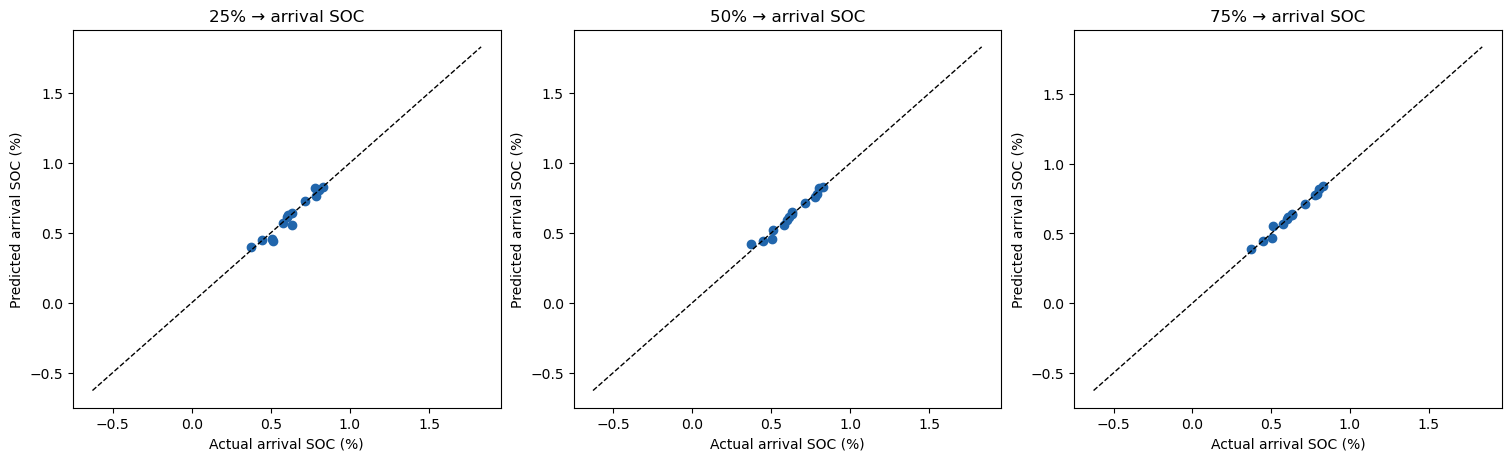

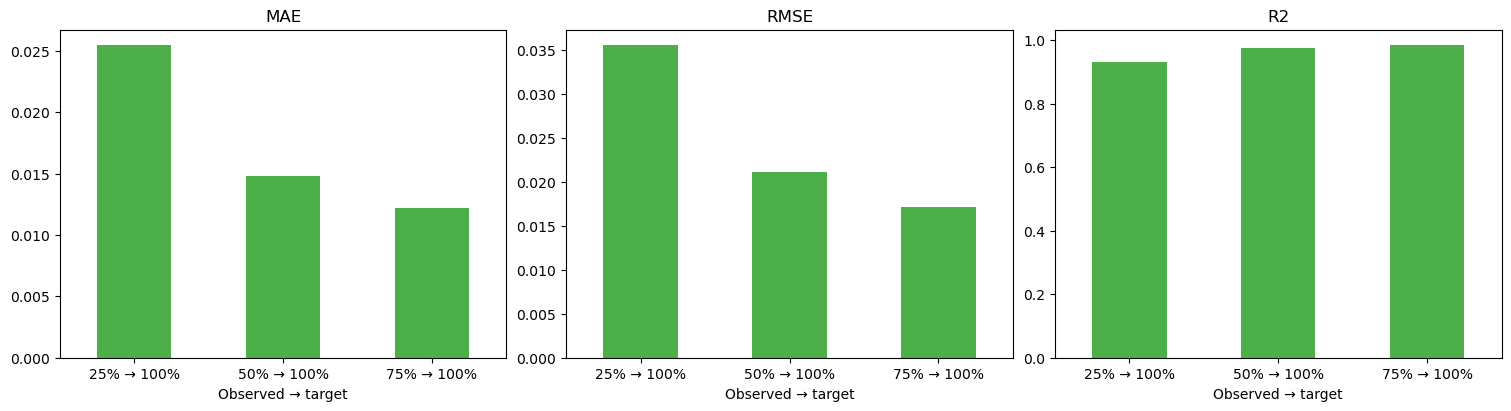

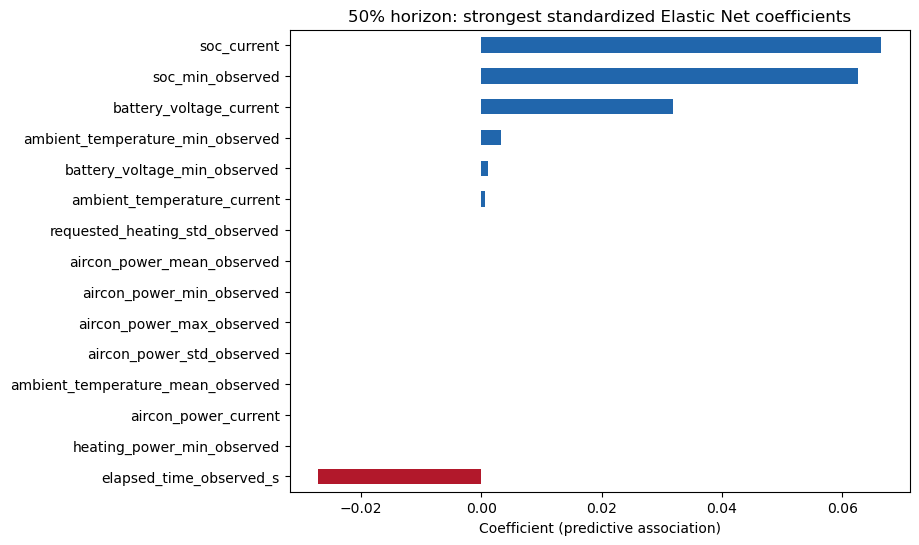

,coefficient
elapsed_time_observed_s,-0.0272
heating_power_min_observed,0.0000
aircon_power_current,0.0000
ambient_temperature_mean_observed,0.0000
aircon_power_std_observed,0.0000
aircon_power_max_observed,0.0000
aircon_power_min_observed,0.0000
aircon_power_mean_observed,0.0000
requested_heating_std_observed,-0.0000
ambient_temperature_current,0.0006


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
for ax, horizon in zip(axes, (0.25, 0.50, 0.75)):
    pred = predictions[horizon]
    ax.scatter(pred["Actual arrival SOC"], pred["Predicted arrival SOC"], color="#2166ac")
    bounds = [min(pred[["Actual arrival SOC", "Predicted arrival SOC"]].min()) - 1,
              max(pred[["Actual arrival SOC", "Predicted arrival SOC"]].max()) + 1]
    ax.plot(bounds, bounds, "k--", lw=1)
    ax.set(title=f"{int(horizon*100)}% → arrival SOC", xlabel="Actual arrival SOC (%)", ylabel="Predicted arrival SOC (%)")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    central_table[metric].plot.bar(ax=ax, color="#4daf4a", rot=0, title=metric)
    ax.set_xlabel("Observed → target")
plt.show()

horizon = 0.50
model = central_models[horizon]
coefs = pd.Series(model.named_steps["model"].coef_, index=datasets[horizon][0].columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).head(15).index).sort_values()
plt.figure(figsize=(8, 6))
top.plot.barh(color=np.where(top >= 0, "#2166ac", "#b2182b"))
plt.title("50% horizon: strongest standardized Elastic Net coefficients")
plt.xlabel("Coefficient (predictive association)")
plt.show()
display(top.to_frame("coefficient").round(4))

## 6. Leakage-safe condition-balanced simulated clients

Munich has no persistent vehicle/driver identifiers. For each horizon, five clients are simulated from training-trip **prefix** operating-condition features only. PCA is fitted on the training partition, trips are ordered by the primary component, and balanced round-robin assignment creates 10–11 trips per client. The target and future telemetry are not used.

In [7]:
CONDITION_COLUMNS = ["soc_start", "soc_current", "ambient_temperature_mean_observed", "battery_temperature_mean_observed",
                     "cabin_temperature_mean_observed", "heating_power_mean_observed", "aircon_power_mean_observed",
                     "velocity_mean_observed", "velocity_std_observed", "velocity_max_observed",
                     "acceleration_mean_observed", "throttle_mean_observed", "motor_torque_mean_observed",
                     "distance_observed_km", "elapsed_time_observed_s"]

def build_clients(X_train):
    cols = [c for c in CONDITION_COLUMNS if c in X_train.columns]
    assert cols and not any("arrival" in c or "end" in c for c in cols)
    condition_scaled = StandardScaler().fit_transform(X_train[cols])
    pcs = PCA(n_components=0.90, random_state=RANDOM_STATE).fit_transform(condition_scaled)
    ordered = np.argsort(pcs[:, 0])
    labels = np.empty(len(X_train), dtype=int)
    for rank, position in enumerate(ordered):
        labels[position] = rank % 5 + 1
    clients = {client: X_train.index[labels == client].to_numpy() for client in range(1, 6)}
    assigned = np.concatenate(list(clients.values()))
    assert len(assigned) == len(X_train) and len(np.unique(assigned)) == len(X_train)
    return clients

client_partitions = {h: build_clients(datasets[h][0].loc[train_ids]) for h in datasets}
for h, clients in client_partitions.items():
    print(f"{int(h*100)}%: " + ", ".join(f"C{k}={len(v)}" for k, v in clients.items()))

25%: C1=11, C2=11, C3=11, C4=10, C5=10
50%: C1=11, C2=11, C3=11, C4=10, C5=10
75%: C1=11, C2=11, C3=11, C4=10, C5=10


## 7. Federated Elastic Net

FedAvg uses training-only scaling, local proximal Elastic Net updates, and sample-weighted server aggregation. The global test set is never allocated to a client. FedPer-style intercept personalization is evaluated separately on small client-local validation sets; it is not forced into the global-test comparison.

In [8]:
def soft_threshold(x, threshold):
    return np.sign(x) * np.maximum(np.abs(x) - threshold, 0)

def local_enet(X, y, coef, intercept, alpha, l1_ratio, learning_rate=0.05, epochs=10, personal_bias=0.0, bias_l2=0.0):
    beta, bias = coef.copy(), float(intercept)
    personal_bias = float(personal_bias)
    n = len(y)
    for _ in range(epochs):
        error = X @ beta + bias + personal_bias - y
        beta -= learning_rate * ((X.T @ error) / n + alpha * (1 - l1_ratio) * beta)
        beta = soft_threshold(beta, learning_rate * alpha * l1_ratio)
        bias -= learning_rate * error.mean()
        if bias_l2:
            personal_bias -= learning_rate * (error.mean() + bias_l2 * personal_bias)
    return beta, bias, personal_bias

def run_fedavg(X_train, y_train, X_test, y_test, clients, alpha, l1_ratio, rounds=100, epochs=3, learning_rate=0.01):
    scaler = StandardScaler().fit(X_train)
    tr, te = scaler.transform(X_train), scaler.transform(X_test)
    position = {trip: i for i, trip in enumerate(X_train.index)}
    coef, intercept, history = np.zeros(tr.shape[1]), float(y_train.mean()), []
    for rnd in range(1, rounds + 1):
        updates = []
        for ids in clients.values():
            idx = [position[t] for t in ids]
            b, a, _ = local_enet(tr[idx], y_train.loc[ids].to_numpy(), coef, intercept, alpha, l1_ratio,
                                  learning_rate=learning_rate, epochs=epochs)
            updates.append((len(idx), b, a))
        total = sum(n for n, _, _ in updates)
        coef = sum(n * b for n, b, _ in updates) / total
        intercept = sum(n * a for n, _, a in updates) / total
        test_pred = te @ coef + intercept
        history.append({"Round": rnd, **metrics(y_test, test_pred)})
    return coef, intercept, scaler, pd.DataFrame(history)

fedavg_rows, fedavg_runs = [], {}
for h, (X, y, _) in datasets.items():
    row = central_table.loc[f"{int(h*100)}% → 100%"]
    coef, intercept, scaler, history = run_fedavg(X.loc[train_ids], y.loc[train_ids], X.loc[test_ids], y.loc[test_ids],
                                                   client_partitions[h], row["alpha"], row["l1_ratio"])
    final = history.iloc[-1]
    fedavg_rows.append({"Model": "FedAvg Elastic Net (global test)", "Horizon": f"{int(h*100)}% → 100%", **final.to_dict()})
    fedavg_runs[h] = (coef, intercept, scaler, history)
fedavg_table = pd.DataFrame(fedavg_rows)
display(fedavg_table.round(4))

,Model,Horizon,Round,MAE,RMSE,R2
0,FedAvg Elastic Net (global test),25% → 100%,100.0,0.0237,0.0269,0.9607
1,FedAvg Elastic Net (global test),50% → 100%,100.0,0.0178,0.0224,0.9728
2,FedAvg Elastic Net (global test),75% → 100%,100.0,0.0134,0.0174,0.9835


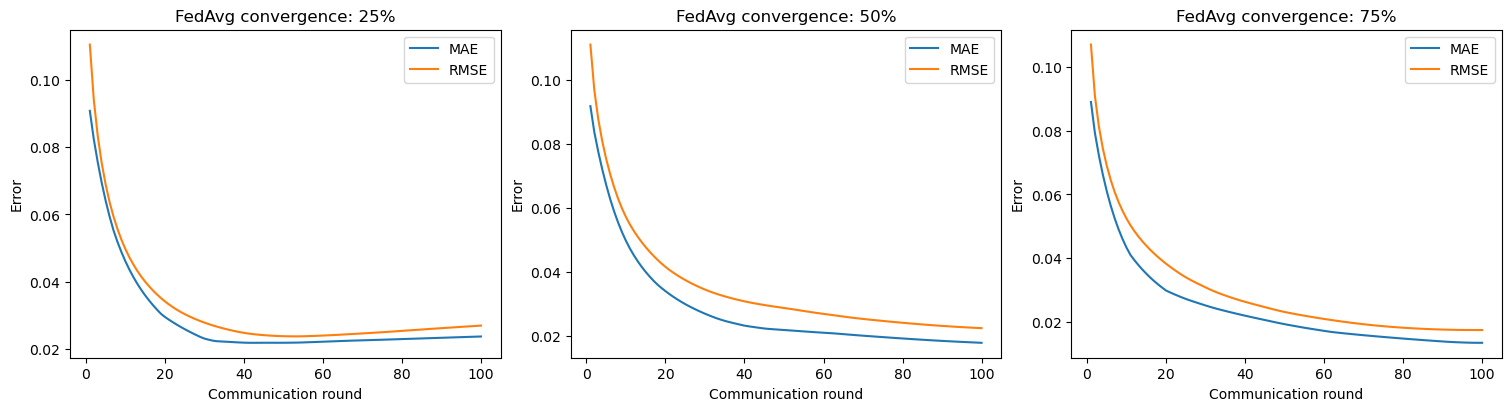

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, h in zip(axes, (0.25, 0.50, 0.75)):
    history = fedavg_runs[h][3]
    ax.plot(history["Round"], history["MAE"], label="MAE")
    ax.plot(history["Round"], history["RMSE"], label="RMSE")
    ax.set(title=f"FedAvg convergence: {int(h*100)}%", xlabel="Communication round", ylabel="Error")
    ax.legend()
plt.show()

## 8. FedPer-style intercept personalization (client-local validation)

Each client is split into local train/validation trips after the global training split. A shared Elastic Net is aggregated from local training data while each client maintains an intercept adjustment. Because each validation set has only 2–3 trips, client-level R² is highly uncertain. These results are reported as client-local validation, not as global-test performance.

In [10]:
def run_fedper_local(X_train, y_train, clients, alpha, l1_ratio, rounds=50, epochs=5):
    local = {}
    for client, ids in clients.items():
        local_train, local_val = train_test_split(ids, test_size=0.20, random_state=RANDOM_STATE)
        local[client] = (local_train, local_val)
    fit_ids = np.concatenate([a for a, _ in local.values()])
    scaler = StandardScaler().fit(X_train.loc[fit_ids])
    X_scaled = pd.DataFrame(scaler.transform(X_train), index=X_train.index)
    coef, intercept = np.zeros(X_train.shape[1]), float(y_train.loc[fit_ids].mean())
    personal = {client: 0.0 for client in clients}
    history = []
    for rnd in range(1, rounds + 1):
        updates = []
        for client, (fit, _) in local.items():
            b, a, p = local_enet(X_scaled.loc[fit].to_numpy(), y_train.loc[fit].to_numpy(), coef, intercept, alpha, l1_ratio,
                                 epochs=epochs, personal_bias=personal[client], bias_l2=0.01)
            personal[client] = p
            updates.append((len(fit), b, a))
        total = sum(n for n, _, _ in updates)
        coef = sum(n * b for n, b, _ in updates) / total
        intercept = sum(n * a for n, _, a in updates) / total
        truth, pred = [], []
        for client, (_, val) in local.items():
            truth.extend(y_train.loc[val])
            pred.extend(X_scaled.loc[val].to_numpy() @ coef + intercept + personal[client])
        history.append({"Round": rnd, **metrics(truth, pred)})
    return pd.DataFrame(history), local

fedper_rows, fedper_runs = [], {}
for h, (X, y, _) in datasets.items():
    row = central_table.loc[f"{int(h*100)}% → 100%"]
    history, local = run_fedper_local(X.loc[train_ids], y.loc[train_ids], client_partitions[h], row["alpha"], row["l1_ratio"])
    best = history.loc[history["MAE"].idxmin()]
    fedper_rows.append({"Model": "FedPer-style intercept (client-local validation)", "Horizon": f"{int(h*100)}% → 100%", **best.to_dict(),
                        "Local validation trips": sum(len(v) for _, v in local.values())})
    fedper_runs[h] = (history, local)
fedper_table = pd.DataFrame(fedper_rows)
display(fedper_table.round(4))

,Model,Horizon,Round,MAE,RMSE,R2,Local validation trips
0,FedPer-style intercept (client-local validation),25% → 100%,1.0,0.0600,0.0806,0.6367,13
1,FedPer-style intercept (client-local validation),50% → 100%,46.0,0.0352,0.0395,0.9645,13
2,FedPer-style intercept (client-local validation),75% → 100%,50.0,0.0210,0.0259,0.9794,13


## 9. Final comparison, application example, and conclusion

The first two model families share a global test protocol. FedPer-style values use a different, client-local validation protocol and are intentionally labelled as such. The example below demonstrates the intended application: during a journey, the system uses observations available so far to estimate SOC at arrival.

,Model,Horizon,MAE,RMSE,R2
0,Centralized Elastic Net (global test),25% → 100%,0.0254,0.0355,0.9316
1,Centralized Elastic Net (global test),50% → 100%,0.0148,0.0211,0.9759
2,Centralized Elastic Net (global test),75% → 100%,0.0122,0.0171,0.9841
3,FedAvg Elastic Net (global test),25% → 100%,0.0237,0.0269,0.9607
4,FedAvg Elastic Net (global test),50% → 100%,0.0178,0.0224,0.9728
5,FedAvg Elastic Net (global test),75% → 100%,0.0134,0.0174,0.9835
6,FedPer-style intercept (client-local validation),25% → 100%,0.0600,0.0806,0.6367
7,FedPer-style intercept (client-local validation),50% → 100%,0.0352,0.0395,0.9645
8,FedPer-style intercept (client-local validation),75% → 100%,0.0210,0.0259,0.9794


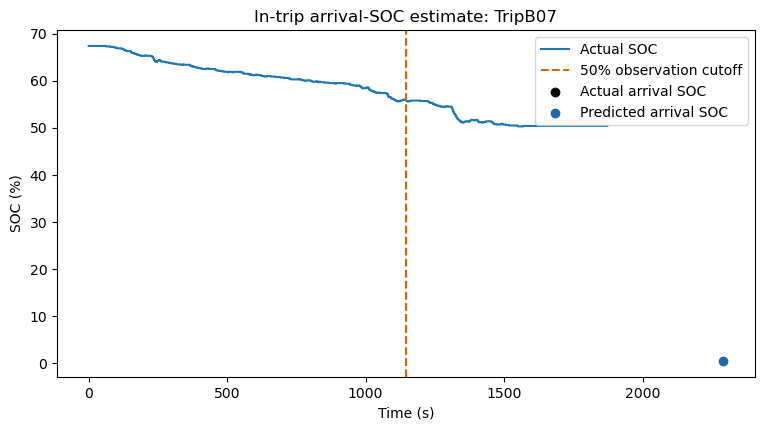

CURRENT OBSERVATION
-------------------
Trip: TripB07 | Progress: 50% | Current SOC: 55.90%
Distance travelled: 8.03 km | Average speed: 25.26 km/h
Heating demand: 2.33 kW | AC demand: 0.00 kW
Battery temperature: 6.00 °C

PREDICTION
----------
Predicted arrival SOC: 0.46%
Actual arrival SOC: 0.50%
Absolute error: 0.05 percentage points


In [11]:
central_global = central_table.reset_index().assign(Model="Centralized Elastic Net (global test)")
fedavg_global = fedavg_table[["Model", "Horizon", "MAE", "RMSE", "R2"]]
fedper_local = fedper_table[["Model", "Horizon", "MAE", "RMSE", "R2"]]
final_comparison = pd.concat([
    central_global.rename(columns={"index": "Horizon"})[["Model", "Horizon", "MAE", "RMSE", "R2"]],
    fedavg_global, fedper_local
], ignore_index=True)
display(final_comparison.round(4))

horizon = 0.50
example_trip = predictions[horizon].iloc[0]["Trip"]
X, y, audit = datasets[horizon]
example_features = X.loc[example_trip]
example_prediction = predictions[horizon].set_index("Trip").loc[example_trip, "Predicted arrival SOC"]
frame = trip_data[example_trip]
time, soc = numeric(frame["Time [s]"]).to_numpy(), numeric(frame["SoC [%]"]).to_numpy()
cutoff = audit.loc[example_trip, "cutoff_time_s"]
plt.figure(figsize=(9, 4.5))
plt.plot(time, soc, label="Actual SOC")
plt.axvline(cutoff, color="#e66101", linestyle="--", label="50% observation cutoff")
plt.scatter([time[-1]], [soc[-1]], color="black", zorder=3, label="Actual arrival SOC")
plt.scatter([time[-1]], [example_prediction], color="#2166ac", zorder=3, label="Predicted arrival SOC")
plt.xlabel("Time (s)"); plt.ylabel("SOC (%)"); plt.title(f"In-trip arrival-SOC estimate: {example_trip}"); plt.legend(); plt.show()

print("CURRENT OBSERVATION")
print("-------------------")
print(f"Trip: {example_trip} | Progress: 50% | Current SOC: {example_features['soc_current']:.2f}%")
print(f"Distance travelled: {example_features['distance_observed_km']:.2f} km | Average speed: {example_features['velocity_mean_observed']:.2f} km/h")
print(f"Heating demand: {example_features['heating_power_mean_observed']:.2f} kW | AC demand: {example_features['aircon_power_mean_observed']:.2f} kW")
print(f"Battery temperature: {example_features['battery_temperature_current']:.2f} °C")
print("\nPREDICTION")
print("----------")
print(f"Predicted arrival SOC: {example_prediction:.2f}%")
print(f"Actual arrival SOC: {y.loc[example_trip]:.2f}%")
print(f"Absolute error: {abs(example_prediction-y.loc[example_trip]):.2f} percentage points")

### Conclusion

This notebook estimates arrival SOC from the SOC and operating conditions observed during a journey. It reports accuracy separately for 25%, 50%, and 75% observation horizons, and evaluates whether a global federated model can approach centralized performance without moving raw telemetry between simulated clients.

Interpret coefficients as predictive associations only. The small 67-trip sample, lack of real vehicle/driver identities, simulated clients, small client-local validation sets, and absence of a large independent fleet-scale test set limit generalization. The workflow nevertheless demonstrates a reproducible, leakage-safe path from observed vehicle state to in-trip arrival-SOC decision support.